# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [3]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [4]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [5]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [6]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv("szkolnictwo_wysze.csv", sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print("dataframe:", df)
print("typy:", df.dtypes)

dataframe:                   name   rok  wartość            zmienna
0   Szkolnictwo wyższe  2012       22           uczelnie
1   Szkolnictwo wyższe  2013       22           uczelnie
2   Szkolnictwo wyższe  2014       23           uczelnie
3   Szkolnictwo wyższe  2015       21           uczelnie
4   Szkolnictwo wyższe  2016       20           uczelnie
..                 ...   ...      ...                ...
60  Szkolnictwo wyższe  2020    14082  absolwenci ogółem
61  Szkolnictwo wyższe  2021    14756  absolwenci ogółem
62  Szkolnictwo wyższe  2022    14479  absolwenci ogółem
63  Szkolnictwo wyższe  2023    14855  absolwenci ogółem
64  Szkolnictwo wyższe  2024    14574  absolwenci ogółem

[65 rows x 4 columns]
typy: name         str
rok        int64
wartość    int64
zmienna      str
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* …
Separator to ";", 
kolumna wartość ma wartość int64,
Nazwy kolumn z polskimi znakami wczytały sie poprawnie

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [7]:
# TODO: jakie są zmienne i ile mają wierszy?
print("wartości zmiennej:", df["zmienna"].dtypes)

print("Jakie są:", df["zmienna"].unique().tolist())

print("ile razy każda kolumna", df["zmienna"].value_counts())

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
# zmienneIndywidualne = list(set(df["zmienna"].array))
# print("Zmienne:", zmienneIndywidualne)
# szeroka = df.set_index("rok")["zmienna"]
# szeroka.head(30)
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")[df["zmienna"].unique().tolist()]
szeroka

wartości zmiennej: str
Jakie są: ['uczelnie', 'ogółem', 'kobiety', 'mężczyźni', 'absolwenci ogółem']
ile razy każda kolumna zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,uczelnie,ogółem,kobiety,mężczyźni,absolwenci ogółem
rok,,,,,
2012,22,91546,55265,36281,24825
2013,22,83471,50007,33464,22590
2014,23,80676,48220,32456,21343
2015,21,76353,45584,30769,19835
2016,20,73961,44053,29908,17662
2017,22,72019,42990,29029,19281
2018,20,65565,39312,26253,17046
2019,19,64443,38146,26297,15819
2020,18,65325,39170,26155,14082


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [8]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
jakieLata = df["rok"].unique().tolist()
print("unikalne lata:", jakieLata)

for rok in jakieLata:
    liczbaOgółem = df[(df["zmienna"] == "ogółem") & (df["rok"] == rok)]["wartość"].item()
    print("liczba ogółem", rok, ":", liczbaOgółem)
    liczbaKobiet = df[(df["zmienna"] == "kobiety") & (df["rok"] == rok)]["wartość"].item()
    print("liczba Kobiet", rok, ":", liczbaKobiet)
    liczbaMężczyzn = df[(df["zmienna"] == "mężczyźni") & (df["rok"] == rok)]["wartość"].item()
    print("liczba Mężczyzn", rok, ":", liczbaMężczyzn)
    realnaWartosc = liczbaKobiet + liczbaMężczyzn
    if (realnaWartosc == liczbaOgółem):
        print("Tyle samo!")
    elif liczbaKobiet > liczbaMężczyzn:
        print("Kobiet jest więcej o:", liczbaKobiet - liczbaMężczyzn)
    else:
        print("Mężczyzn jest wiecej o:", liczbaMężczyzn - liczbaKobiet)



unikalne lata: [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
liczba ogółem 2012 : 91546
liczba Kobiet 2012 : 55265
liczba Mężczyzn 2012 : 36281
Tyle samo!
liczba ogółem 2013 : 83471
liczba Kobiet 2013 : 50007
liczba Mężczyzn 2013 : 33464
Tyle samo!
liczba ogółem 2014 : 80676
liczba Kobiet 2014 : 48220
liczba Mężczyzn 2014 : 32456
Tyle samo!
liczba ogółem 2015 : 76353
liczba Kobiet 2015 : 45584
liczba Mężczyzn 2015 : 30769
Tyle samo!
liczba ogółem 2016 : 73961
liczba Kobiet 2016 : 44053
liczba Mężczyzn 2016 : 29908
Tyle samo!
liczba ogółem 2017 : 72019
liczba Kobiet 2017 : 42990
liczba Mężczyzn 2017 : 29029
Tyle samo!
liczba ogółem 2018 : 65565
liczba Kobiet 2018 : 39312
liczba Mężczyzn 2018 : 26253
Tyle samo!
liczba ogółem 2019 : 64443
liczba Kobiet 2019 : 38146
liczba Mężczyzn 2019 : 26297
Tyle samo!
liczba ogółem 2020 : 65325
liczba Kobiet 2020 : 39170
liczba Mężczyzn 2020 : 26155
Tyle samo!
liczba ogółem 2021 : 66002
liczba Kobiet 2021 : 39958
liczba

## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [9]:
# TODO: statystyki opisowe
for kolumna in df.columns.to_list():
    print("Opis kolumny:", kolumna,":", df[kolumna].describe())

# TODO: zmiana procentowa 2012 → 2024
unikalneZmienne = df["zmienna"].unique().tolist()

for zmienna in unikalneZmienne:
    r2012 = df[(df["zmienna"] == zmienna) & (df["rok"] == 2012)]["wartość"].item()
    # print("wartośćććććććććć", r2012)
    r2024 = df[(df["zmienna"] == zmienna) & (df["rok"] == 2024)]["wartość"].item()
    spadekDoProcent = (r2024/r2012) * 100
    # print("Różnica 2024 - 2012 ", zmienna, ":", r2024-r2012)
    print("Wartość", zmienna, "w 2024 roku stanowi", spadekDoProcent, "% z roku 2012")

# TODO: nowe kolumny
# dla każdego roku dodać dodatkową wartość ze zmienną udział kobiet i obliczeniami w stylu: 
iloscOgolem = df[(df["zmienna"] == "ogółem")].set_index("rok")["wartość"]
iloscKobiet = df[(df["zmienna"] == "kobiety")].set_index("rok")["wartość"]
udzialKobiet = iloscKobiet / iloscOgolem
# print("dodaj w roku", rok, "kobiety:", udzialKobiet, "%")
df["udzial_kobiet"] = df["rok"].map(udzialKobiet)
print("tabela:", df.head(10))

studenci = df[df["zmienna"] == "ogółem"].set_index("rok")["wartość"]
ilośćUczelni = df[df["zmienna"] == "uczelnie"].set_index("rok")["wartość"]
iloscStudentowNaUczelnie = studenci / ilośćUczelni
# print("Ilosc studentow na uczlenie", iloscStudentowNaUczelnie)
df["studenci_na_uczelnie"] = df["rok"].map(iloscStudentowNaUczelnie)

print("tabela ze studentami:", df.head(11))



Opis kolumny: name : count                     65
unique                     1
top       Szkolnictwo wyższe
freq                      65
Name: name, dtype: object
Opis kolumny: rok : count     65.00
mean    2018.00
std        3.77
min     2012.00
25%     2015.00
50%     2018.00
75%     2021.00
max     2024.00
Name: rok, dtype: float64
Opis kolumny: wartość : count      65.00
mean    32281.95
std     24944.87
min        15.00
25%     14756.00
50%     26297.00
75%     45584.00
max     91546.00
Name: wartość, dtype: float64
Opis kolumny: zmienna : count           65
unique           5
top       uczelnie
freq            13
Name: zmienna, dtype: object
Wartość uczelnie w 2024 roku stanowi 68.18181818181817 % z roku 2012
Wartość ogółem w 2024 roku stanowi 70.20732746378869 % z roku 2012
Wartość kobiety w 2024 roku stanowi 69.77653125848185 % z roku 2012
Wartość mężczyźni w 2024 roku stanowi 70.86353738871586 % z roku 2012
Wartość absolwenci ogółem w 2024 roku stanowi 58.70694864048338 % z ro

## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

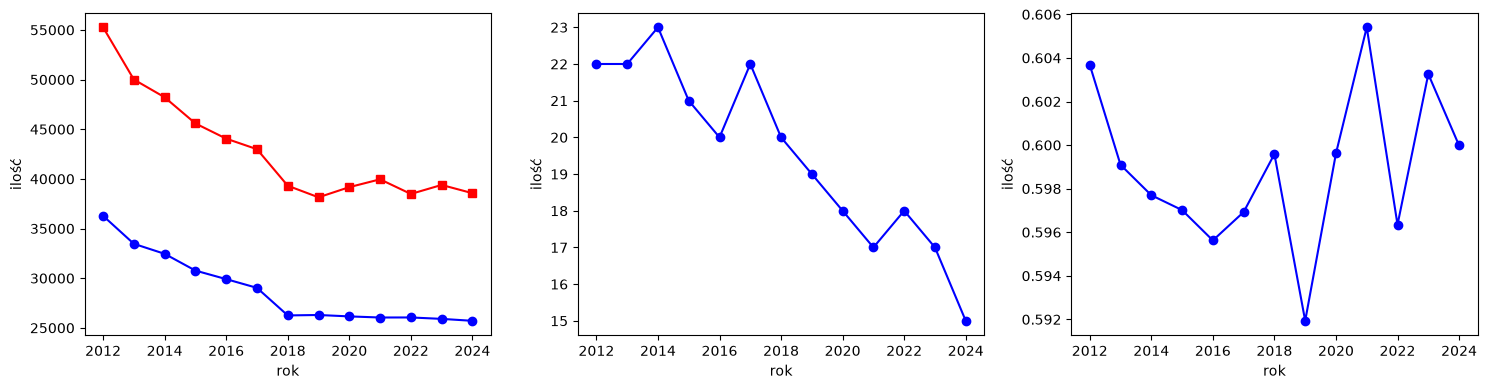

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="o", color="blue", label="mężczyźni")
axes[0].plot(szeroka.index, szeroka["kobiety"], marker="s", color="red", label="kobiety")
axes[0].set_xlabel("rok")
axes[0].set_ylabel("ilość")

# TODO: wykres 2 — uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="blue", label="uczelnie")
axes[1].set_xlabel("rok")
axes[1].set_ylabel("ilość")

# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["kobiety"] / szeroka["ogółem"], marker="o", color="blue", label="udział kobiet")
# axes[2].plot(szeroka.index, szeroka["kobiety"], marker="s", color="red", label="kobiety")
axes[2].set_xlabel("rok")
axes[2].set_ylabel("ilość")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* …
Ilość studentów i uczelnie zauważalnie spadła ale ilość kobiet jest bardzo stabilna

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** … · **link:** … · **data pobrania:** …

In [35]:
# TODO: wczytanie i przegląd Twojego zbioru
# 1.
# Link do strony: https://otwarte.miasto.lodz.pl/raporty/
# Nazwa: "Wypadki drogowe.csv"
# Link do pobrania: https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/07/wypadki_drogowe.csv

df = pd.read_csv("wypadki_drogowe.csv", sep=";")

# 2.
print("wypadki:", df.head())
# 3.
# są w długim
szeroki = df.pivot(index="rok", columns="zmienne", values="wartość")
print(szeroki.head())

# 4.
print("Isna:", df.isna().sum())
# Nie ma braków.


# 5.
print("Statystyki:", szeroki.describe())



wypadki:      id                    name   rok  wartość         zmienne
0  7849  Bezpieczeństwo drogowe  2011     1826  Wypadki ogółem
1  7849  Bezpieczeństwo drogowe  2012     1668  Wypadki ogółem
2  7849  Bezpieczeństwo drogowe  2013     1716  Wypadki ogółem
3  7849  Bezpieczeństwo drogowe  2014     1791  Wypadki ogółem
4  7849  Bezpieczeństwo drogowe  2015     1715  Wypadki ogółem
zmienne  Ofiary śmiertelne  Wypadki ogółem
rok                                       
2011                    38            1826
2012                    33            1668
2013                    31            1716
2014                    42            1791
2015                    19            1715
Isna: id         0
name       0
rok        0
wartość    0
zmienne    0
dtype: int64
Statystyki: zmienne  Ofiary śmiertelne  Wypadki ogółem
count                14.00           14.00
mean                 23.00         1389.07
std                   9.60          399.48
min                  10.00          846.00
2

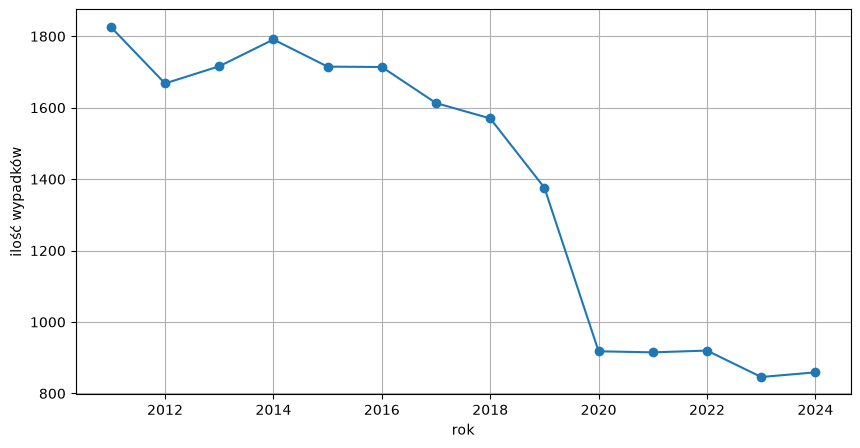

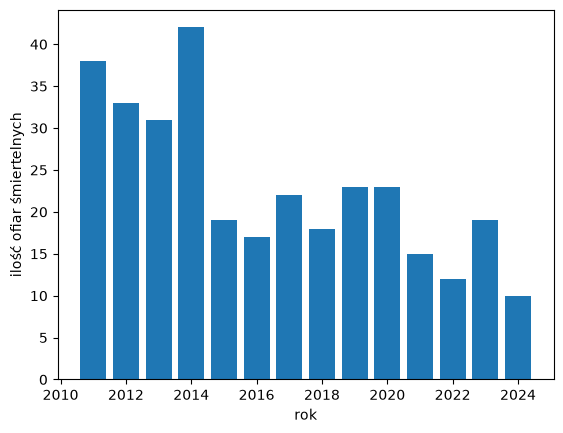

In [41]:
# TODO: przekształcenia, statystyki i wykresy
# 6.
plt.figure(figsize=(10, 5))

plt.plot(szeroki.index, szeroki["Wypadki ogółem"], marker="o")
plt.xlabel("rok")
plt.ylabel("ilość wypadków")
plt.grid(True)
plt.show()

plt.bar(szeroki.index, szeroki["Ofiary śmiertelne"])
plt.xlabel("rok")
plt.ylabel("ilość ofiar śmiertelnych")
plt.show()

In [43]:
✍️ **Wnioski:** …
# Między 2018 a 2020 rokiem zauważalnie zmalała ilość wypadków. Wykres nie zaczyna się od 0, dlatego różnica jest większa.
# W przypadku ilości ofiar śmiertelnych zauważalny ale nie znaczący z perspektywy wykresu spadek nastąpił z 2014 na 2015.
# Realnie różnica w obu przypadkach jest zauważalna, jednak przedstawienie pierwszego wykresu znacząco poprawia jego wizualny rezultat.

SyntaxError: invalid character '✍' (U+270D) (2306106238.py, line 1)

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [54]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

statystyki:           age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


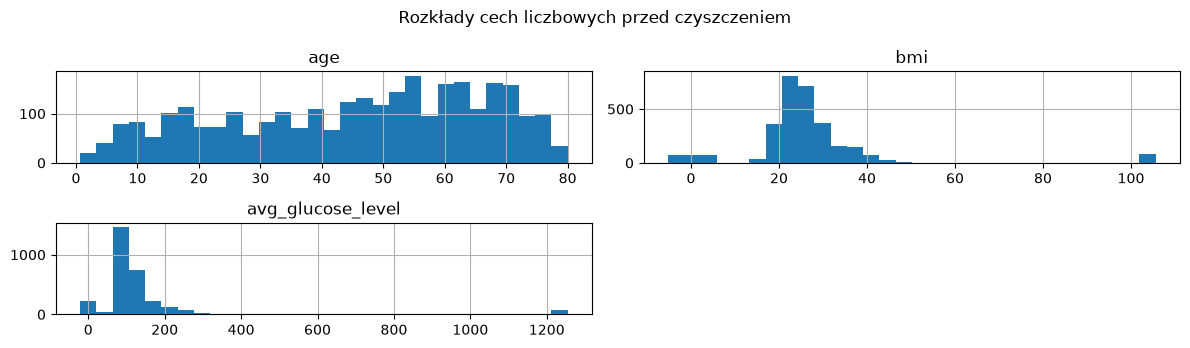

In [55]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
print("statystyki:", pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 3.5))
plt.suptitle("Rozkłady cech liczbowych przed czyszczeniem")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* …
# minimalne i maksymalne u człowieka wartości to:
# age: najstarsza osoba żyła 122 lata, więc dowolna wartość powyżej nie ma sensu.
# bmi: według google od 12 do 40, więc taki bym przyjął jako "możliwy", więc tutaj wartości minimalne i maksymalne są poza normą (szczególnie -5)
# avg_glucose_level: tutaj od razu moge powiedzieć, ze -21 jest niemożliwy, tak samo cukier powyżej 1000 jest niemożliwy do przeżycia.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [64]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# TODO: liczebności
niemozliwe = zle_bmi | zla_glukoza | zly_wiek
print("bmi:", zle_bmi.sum())
print("avg glukoza:", zla_glukoza.sum())
print("wiek:", zly_wiek.sum())
print("minimalnie:", niemozliwe.sum())

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan
print("złe bmi:", pacjenci.loc[zle_bmi].head())
print("zła glukoza:", pacjenci.loc[zla_glukoza].head())
print("zły wiek:", pacjenci.loc[zly_wiek].head())

bmi: 300
avg glukoza: 300
wiek: 0
minimalnie: 560
złe bmi:    patient_id  gender   age  hypertension  heart_disease  ever_married  \
5     A333278    Male 31.00             0              0          True   
50    A942523    Male 13.00             0              0         False   
61    A178712  Female  9.00             0              0         False   
85    A444169    Male  8.00             0              0         False   
92    A139343    Male 36.00             0              0          True   

        work_type residence_type  avg_glucose_level  bmi   smoking_status  \
5    Never_worked          Urban              99.28  NaN  formerly smoked   
50       children          Rural             165.23  NaN          Unknown   
61       children          Rural             100.42  NaN     never smoked   
85       children          Urban             104.09  NaN     never smoked   
92  Self-employed          Urban             166.56  NaN  formerly smoked   

    stroke  
5        0  
50     

statystyki:           age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91
błedy w wartościach: age                    0
bmi                  300
avg_glucose_level    300
dtype: int64


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'bmi'}>],
       [<Axes: title={'center': 'avg_glucose_level'}>, <Axes: >]],
      dtype=object)

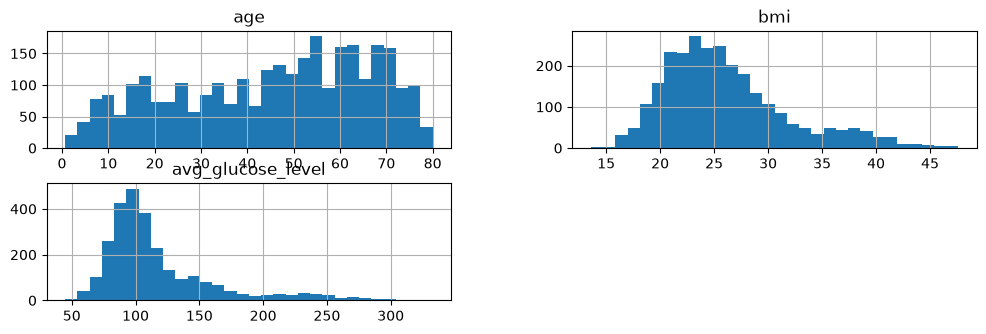

In [ ]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
print("statystyki:", pacjenci[LICZBOWE].describe())

print("błedy w wartościach:", pacjenci[LICZBOWE].isna().sum())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 3.5))
#Teraz wykresy wyglądają logicznie i możliwie

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

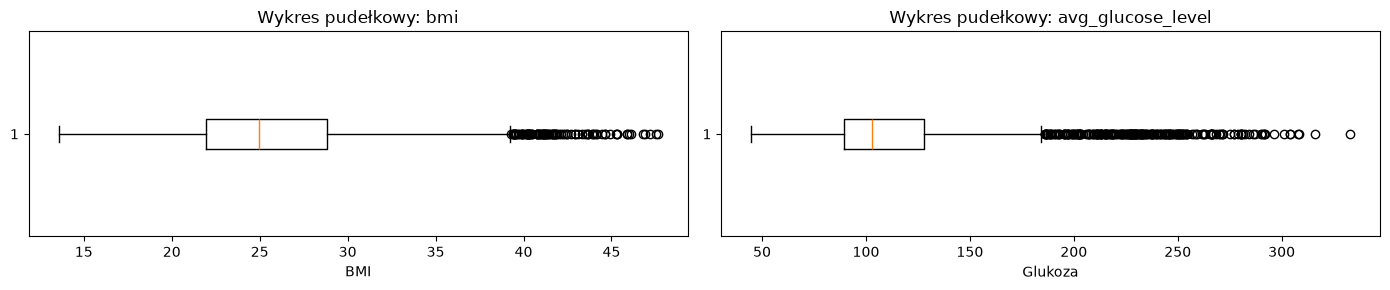

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
for ax, kolumna, podpis in zip(
    axes, ["bmi", "avg_glucose_level"], ["BMI", "Glukoza"]
):
    ax.boxplot(pacjenci[kolumna].dropna(), orientation="horizontal")
    ax.set_title(f"Wykres pudełkowy: {kolumna}")
    ax.set_xlabel(podpis)

plt.tight_layout()
plt.show()

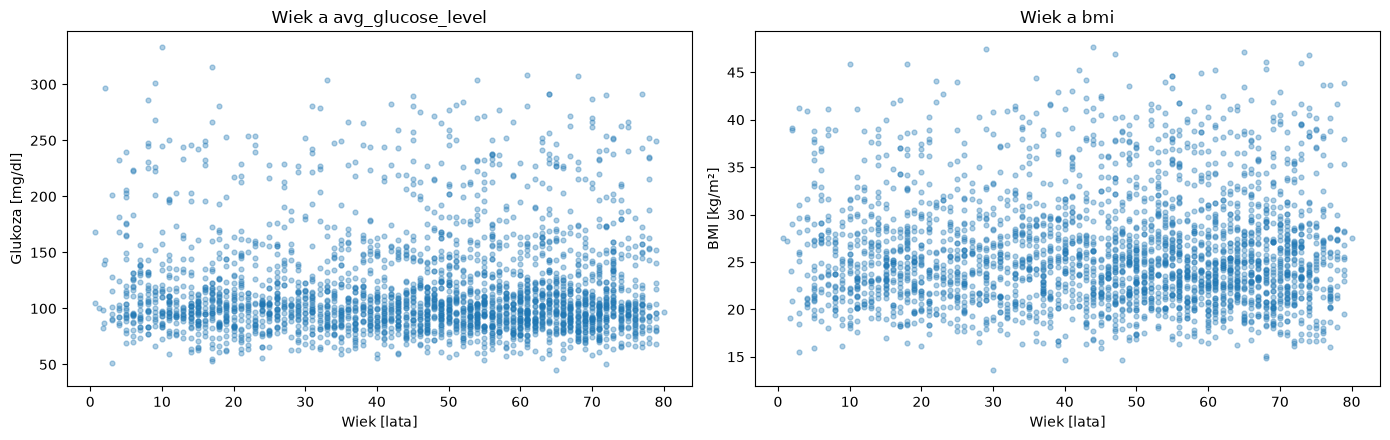

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
for ax, kolumna, podpis in zip(
    axes, ["avg_glucose_level", "bmi"], ["glukoza", "bmi"]
):
    ax.scatter(pacjenci["age"], pacjenci[kolumna], alpha=0.35, s=12)
    ax.set_xlabel("Wiek [lata]")
    ax.set_ylabel(podpis)
    ax.set_title(f"Wiek a {kolumna}")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* …
1. Na oko wydaję sie, ze wiecej jest zmiennej glukozy oraz w obu pryzpakdach występuja tylko po jednej stronie.
2. Nie powinien to być błąd, patrząc an wykres widać, że wysoki cunkier nawet w nowym wieku jest statystycznie normalny.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [74]:
def maska_iqr(s, k=1.5):
    # TODO
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).fillna(False)

def maska_z(s, prog=3):
    # TODO
    odch = s.std()
    if pd.isna(odch) or odch == 0:
        return pd.Series(False, index=s.index)
    return ((s - s.mean()).abs() / odch > prog).fillna(False)

def maska_mad(s, prog=3.5):
    # TODO
    med = s.median()
    mad = (s - med).abs().median()
    if pd.isna(mad) or mad == 0:
        return pd.Series(False, index=s.index)
    return ((0.6745 * (s - med) / mad).abs() > prog).fillna(False)

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [75]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame(index=LICZBOWE)
porownanie["IQR 1.5"] = [maska_iqr(pacjenci[c]).sum() for c in LICZBOWE]
porownanie["IQR 3"] = [maska_iqr(pacjenci[c], k=3).sum() for c in LICZBOWE]
porownanie["z-score"] = [maska_z(pacjenci[c]).sum() for c in LICZBOWE]
porownanie["MAD"] = [maska_mad(pacjenci[c]).sum() for c in LICZBOWE]
porownanie["skośność"] = pacjenci[LICZBOWE].skew()
print(porownanie)

                   IQR 1.5  IQR 3  z-score  MAD  skośność
age                      0      0        0    0     -0.33
bmi                    100      0       23   33      0.99
avg_glucose_level      235     81       62  223      1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* …
Różne metody mają różną wrażliwość na prawy ogon. Wiek jest stabilny i nie widocznych ogonów.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

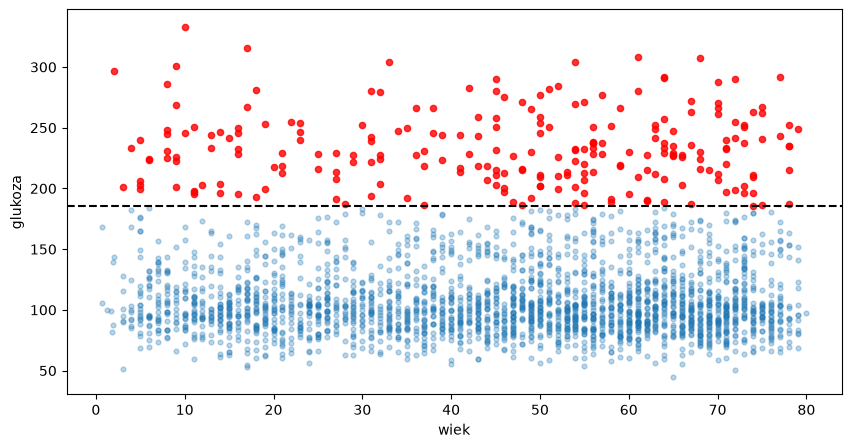

nad granicą: 235
poniżej granicy: 0


In [81]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
m_glukoza = maska_iqr(pacjenci["avg_glucose_level"])
s = pacjenci["avg_glucose_level"]
q1, q3 = s.quantile([0.25, 0.75])
granica = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(pacjenci.loc[~m_glukoza, "age"], pacjenci.loc[~m_glukoza, "avg_glucose_level"], alpha=0.3, s=12,)
ax.scatter(pacjenci.loc[m_glukoza, "age"], pacjenci.loc[m_glukoza, "avg_glucose_level"], alpha=0.8, s=20, color="red")
ax.axhline(granica, linestyle="--", color="black", label=f"granica: {granica:.1f}")
ax.set_xlabel("wiek")
ax.set_ylabel("glukoza")
plt.show()
print("nad granicą:", (s > granica).sum())
print("poniżej granicy:", (s < q1 - 1.5 * (q3-q1)).sum())

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Glukoza odstająca: 235
Pozostali: 2765
Odsetek udarów [%]: avg_glucose_level
False   21.92
True    21.70
Name: stroke, dtype: float64


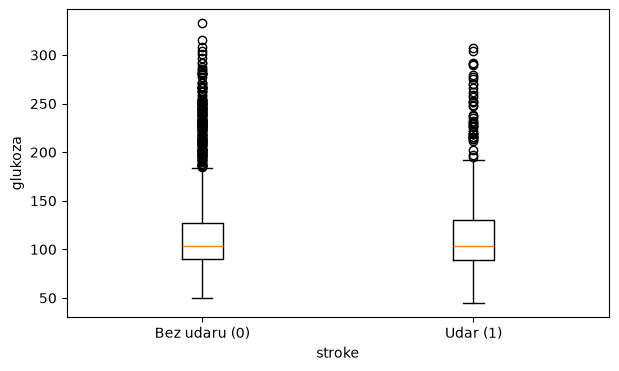

In [90]:
# TODO: odsetek udarów w obu grupach
print("Glukoza odstająca:", m_glukoza.sum())
print("Pozostali:", (~m_glukoza).sum())
print("Odsetek udarów [%]:", pacjenci.groupby(m_glukoza)["stroke"].mean().mul(100))

# TODO: boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([pacjenci.loc[pacjenci["stroke"] == 0, "avg_glucose_level"].dropna(),
            pacjenci.loc[pacjenci["stroke"] == 1, "avg_glucose_level"].dropna()],
           tick_labels=["Bez udaru (0)", "Udar (1)"])
ax.set_xlabel("stroke")
ax.set_ylabel("glukoza")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* …
Ogon jest mniejszy, ale nie jest to sytuacja gdzie nic nie występuje, więc usunięcie mogłobybyć błędem.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [94]:
# TODO: tabela krzyżowa
print("tabela krzywa:", pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

# TODO: maski
dziecko_pali = (pacjenci["work_type"].eq("children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"]))
maluch_student = (pacjenci["age"].le(3) & pacjenci["work_type"].eq("student"))

print("Dziecko i palenie:", dziecko_pali.sum())
print("Wiek <= 3 i student:", maluch_student.sum())


tabela krzywa: smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75
Dziecko i palenie: 15
Wiek <= 3 i student: 1


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* …
To wykrywa wartości pojedyńczych danych, a nie kombinacje nie logiczne, więc może nie wykryć, ale przez tego rodzaju kombinacje, może sie w danych zdażyć, że akurat sie pokryje.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [98]:
# %pip install scipy
from scipy.stats import chi2

# TODO
X = pacjenci[LICZBOWE].dropna().copy()
Z = (X - X.mean()) / X.std()
kwadraty = Z.pow(2)
d2 = kwadraty.sum(axis=1)
prog = chi2.ppf(0.99, df=len(LICZBOWE))
odstajace_d2 = d2 > prog

print("chi2:", prog)
print("d2:", odstajace_d2.sum())
print("cechy:", kwadraty.loc[odstajace_d2].idxmax(axis=1).value_counts())

chi2: 11.344866730144373
d2: 73
cechy: avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

log: 31


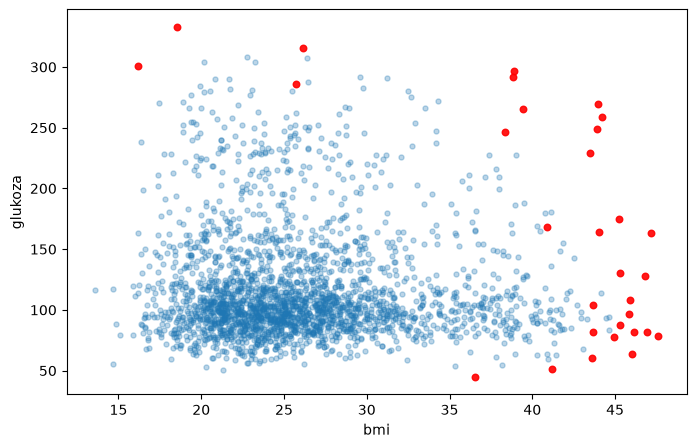

korelacje:                    age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


In [102]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = Z_log.pow(2).sum(axis=1)
odstajace_log = d2_log > prog

print("log:", odstajace_log.sum())

# TODO: wykres punktowy
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X.loc[~odstajace_log, "bmi"], X.loc[~odstajace_log, "avg_glucose_level"],alpha=0.3, s=13)
ax.scatter(X.loc[odstajace_log, "bmi"], X.loc[odstajace_log, "avg_glucose_level"], alpha=0.9, color="red", s=22)
ax.set_xlabel("bmi")
ax.set_ylabel("glukoza")
plt.show()
print("korelacje:", X.corr())

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* …
Mahalanobis uwzględnia korelacje, więc raczej nie.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [ ]:
# TODO: ramka flagi
flagi = ...


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | … | … |
| wysoka glukoza (IQR) | … | … |
| nielogiczne kategorie | … | … |
| odlegli od środka | … | … |